# E4.02.5 — Does full512 acoustic fusion beat full512 Whisper alone?

Compare **frozen Whisper-base.en full512** with **Fusion SVM 512+65** on the fixed 40,000-clip dataset.

| Rule | Both models |
| --- | --- |
| Audio, embeddings and split | Reuse the verified 24 October data |
| C grid | 0.01, 0.1, 1, 10; select validation BA, then macro F1, then smaller C |
| Final fit | 33,881 development clips; 8,443 speakers |
| Calibration | Same five speaker folds; sigmoid; `ensemble=False` |
| Test | Same 6,119 clips; 1,482 speakers |
| Primary comparison | Calibrated fusion minus calibrated Whisper BA at p ≥ 0.50 |
| Uncertainty | 2,000 paired whole-speaker samples within each class; seed 42 |

Use the **Singlish final fusion (Python 3.14)** kernel and **Run All**. Resume checks reuse only outputs with the same code, settings and input hashes. No Whisper encoder is trained. No threshold, branch weight or new architecture is selected on test scores.

The 65 acoustic columns come from the completed **A1 training-only ranking**, not the older development ranking. Reuse the verified Whisper C search. Fit only the missing fusion C trials. Fit both calibrated pipelines in this run.

This is a retrospective comparison: earlier tests informed the choice to try full512 fusion. It is not a new independent test. Source and class remain linked. Calibration folds hold acoustic columns and C fixed; selection is not repeated inside each fold.

In [1]:
import os
for variable in ['OMP_NUM_THREADS','OPENBLAS_NUM_THREADS','MKL_NUM_THREADS','NUMEXPR_NUM_THREADS']:
    os.environ[variable] = '4'
from pathlib import Path
from time import perf_counter
from datetime import datetime, timezone
from importlib.metadata import version
from concurrent.futures import ThreadPoolExecutor, as_completed
import hashlib, json, platform
import joblib, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
    confusion_matrix, roc_auc_score, brier_score_loss, log_loss)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from threadpoolctl import threadpool_limits

ROOT = Path('/home/mh/nusproj/singlish-whisper')
NOTEBOOK = ROOT / 'notebooks/E4_02_5_frozen_full512_vs_fusion_calibrated.ipynb'
A1 = ROOT / 'outputs/a1_tuned_acoustic_whisper_fusion_40000'
E2 = ROOT / 'outputs/frozen_whisper_40000_20261028'
UPSTREAM = Path('/home/mh/nusproj/E1_Feature_EngineeringV4/outputs')
OUT = ROOT / 'outputs/e4_02_5_frozen_full512_vs_fusion_calibrated_20261029'
OUT.mkdir(exist_ok=True)
SEED, REPEATS, FOLDS = 42, 2000, 5
C_VALUES = [0.01, 0.1, 1., 10.]
WHISPER, FUSION = 'Whisper full512 SVM', 'Fusion SVM 512+65 (A2)'
NAMES = [WHISPER, FUSION]
SLUG = {WHISPER:'whisper_full512', FUSION:'fusion_full512_acoustic65'}
PACKAGES = {p:version(p) for p in ['numpy','pandas','scipy','scikit-learn','joblib','matplotlib']}
START = datetime.now(timezone.utc).isoformat()
INPUT_HASHES = {}
def sha(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as f:
        for block in iter(lambda:f.read(1024*1024),b''):h.update(block)
    return h.hexdigest()
def protect(path, expected=None):
    path=Path(path);actual=sha(path)
    if expected is not None:assert actual==expected, f'Input changed: {path}'
    INPUT_HASHES[str(path)]=actual
    return path

def write_json(path, value):
    path=Path(path);temp=path.with_name(path.name+'.tmp')
    temp.write_text(json.dumps(value,indent=2,allow_nan=False)+'\n');temp.replace(path)
def dump(path,value):
    path=Path(path);temp=path.with_name(path.name+'.tmp')
    joblib.dump(value,temp,compress=3);temp.replace(path)
code_text='\n\n'.join(''.join(c['source']) for c in json.loads(NOTEBOOK.read_text())['cells'] if c['cell_type']=='code')
CODE_SHA=hashlib.sha256(code_text.encode()).hexdigest()
print('Python:',platform.python_version(),'| scikit-learn:',PACKAGES['scikit-learn'])
print('New output:',OUT,flush=True)

Python: 3.14.7 | scikit-learn: 1.9.1
New output: /home/mh/nusproj/singlish-whisper/outputs/e4_02_5_frozen_full512_vs_fusion_calibrated_20261029


## 1. Verify saved inputs and training-only columns

Verify A1's input hashes. Check all clip IDs, labels, speakers, splits and cache widths. Check the exact frozen encoder revision. No audio is prepared again. A1 already decoded and verified all 40,000 clips; this run verifies the same saved caches and manifest by hash.

In [2]:
a1=json.loads(protect(A1/'run_record.json').read_text())
assert a1['status']=='complete' and a1['audio_audit']['status']=='passed'
assert a1['settings']['ranking_rows']=='original training only'
assert a1['settings']['final_columns']=='keep training-selected 65 fixed'
assert a1['settings']['C_values']==C_VALUES
for p,expected in a1['input_hashes'].items():protect(p,expected)
# Keep prior notebooks and runtime configuration under read-only hash checks.
for name in ['E4_02_1_tuned_acoustic_svm_whisper_and_fusion.ipynb',
             'E4_02_2_finetuned_whisper_svm_and_fusion.ipynb',
             'E4_02_3_fusion_enabled.ipynb','E4_02_4_finetuned_feature_ablation.ipynb']:
    protect(ROOT/'notebooks'/name)
for p in ['mvp/models/manifest.json','mvp/models.py']:
    protect(Path('/home/mh/nusproj/Singlish')/p)
for name in ['numpy','scipy','scikit-learn','joblib']:
    assert PACKAGES[name]==a1['packages'][name],(name,PACKAGES[name],a1['packages'][name])
COLS=np.asarray(a1['selected_columns'],dtype=int)
assert len(COLS)==len(set(COLS))==65
ranking=pd.DataFrame(a1['acoustic_ranking']).sort_values('rank')
assert ranking.loc[ranking.selected,'column_in_91'].tolist()==COLS.tolist()
manifest=pd.read_csv(UPSTREAM/'e1_feature_study_accent_40000/speaker_splits.csv',keep_default_na=False)
assert len(manifest)==40000 and manifest.clip_id.is_unique
assert manifest.groupby('speaker_group').split.nunique().eq(1).all()
assert manifest.groupby('speaker_group').label.nunique().eq(1).all()
with np.load(UPSTREAM/'e1_feature_study_accent_40000/acoustic_features_91.npz',allow_pickle=False) as z:
    for key,values in [('clip_ids',manifest.clip_id),('labels',manifest.label),('groups',manifest.speaker_group)]:
        np.testing.assert_array_equal(z[key],values)
    acoustic=z['features'].copy()
    feature_names=z['feature_names'][COLS].tolist()
assert feature_names==a1['selected_feature_names']
with np.load(a1['whisper']['cache_path'],allow_pickle=False) as z:
    for key,values in [('clip_ids',manifest.clip_id),('labels',manifest.label),('groups',manifest.speaker_group)]:
        np.testing.assert_array_equal(z[key],values)
    W=z['features'].copy()
    provenance=json.loads(str(z['provenance_json'].item()))
assert W.shape==(40000,512) and acoustic.shape==(40000,91)
assert np.isfinite(W).all() and np.isfinite(acoustic).all()
assert provenance['resolved_revision']=='911407f4214e0e1d82085af863093ec0b66f9cd6'
X={WHISPER:W,FUSION:np.column_stack([acoustic[:,COLS].astype(np.float32),W])}
y=manifest.label.to_numpy();groups=manifest.speaker_group.to_numpy()
IDX={name:np.flatnonzero(manifest.split.eq(name)) for name in ['train','validation','test']}
IDX['development']=np.sort(np.r_[IDX['train'],IDX['validation']])
assert [len(IDX[k]) for k in ['train','validation','test']]==[27797,6084,6119]
assert not set(groups[IDX['development']])&set(groups[IDX['test']])
CONFIG=dict(seed=SEED,C_values=C_VALUES,folds=FOLDS,bootstrap=REPEATS,threshold=.5,
    selected_columns=COLS.tolist(),column_selection='A1 training only; fixed inside calibration',
    branch_weights={'acoustic':float(1/np.sqrt(65)),'whisper':float(1/np.sqrt(512))},
    primary='calibrated fusion minus calibrated full512 Whisper balanced accuracy',
    calibration='sigmoid; ensemble=False; same StratifiedGroupKFold indices',
    code_sha256=CODE_SHA,input_hashes=INPUT_HASHES,packages=PACKAGES)
SIGNATURE=hashlib.sha256(json.dumps(CONFIG,sort_keys=True).encode()).hexdigest()
write_json(OUT/'protocol.json',dict(**CONFIG,signature=SIGNATURE,started_utc=START))
summary=manifest.groupby('split').agg(clips=('clip_id','size'),speakers=('speaker_group','nunique'))
display(summary)
print('Verified cache hashes and fixed split. Frozen encoder revision:',provenance['resolved_revision'])
print('Training-ranked acoustic columns:',len(COLS),'| No PCA.',flush=True)

,clips,speakers
split,,
test,6119,1482
train,27797,6939
validation,6084,1504


Verified cache hashes and fixed split. Frozen encoder revision: 911407f4214e0e1d82085af863093ec0b66f9cd6
Training-ranked acoustic columns: 65 | No PCA.


## 2. Define the fixed pipelines and select C

Whisper alone uses a standard scaler and one RBF SVM. Fusion scales each block, divides each block by the square root of its width, joins the blocks, and fits one RBF SVM. Class weights are balanced. `gamma='scale'`.

The completed E2 C search uses these same training and validation clips. Its files and package versions were verified above. Reuse that search. Fit the four missing fusion trials on training clips only. Each scaler fits inside its training pipeline. Save each trial so an interrupted run can resume.

In [3]:
def make_model(name,c):
    svm=SVC(C=float(c),kernel='rbf',gamma='scale',class_weight='balanced',
            random_state=SEED,cache_size=512)
    if name==WHISPER:
        return Pipeline([('scale',StandardScaler()),('classifier',svm)])
    pre=ColumnTransformer([
        ('acoustic',StandardScaler(),list(range(65))),
        ('whisper',StandardScaler(),list(range(65,577)))],
        transformer_weights={'acoustic':1/np.sqrt(65),'whisper':1/np.sqrt(512)})
    return Pipeline([('preprocess',pre),('classifier',svm)])

def scores(labels,pred,rank,prob=None):
    tn,fp,fn,tp=confusion_matrix(labels,pred,labels=[0,1]).ravel()
    row=dict(accuracy=float(accuracy_score(labels,pred)),balanced_accuracy=float(balanced_accuracy_score(labels,pred)),
        macro_f1=float(f1_score(labels,pred,average='macro')),roc_auc=float(roc_auc_score(labels,rank)),
        false_positive=int(fp),false_negative=int(fn),errors=int(fp+fn),
        singapore_recall=float(tp/(tp+fn)),non_singapore_specificity=float(tn/(tn+fp)))
    if prob is not None:row.update(brier_score=float(brier_score_loss(labels,prob)),log_loss=float(log_loss(labels,prob)))
    return row

trials=pd.read_csv(E2/'validation_C_trials.csv')
trials=trials.loc[trials.model.eq(WHISPER)].copy()
assert sorted(trials.C)==C_VALUES
trials['origin']='verified completed E2 search'
progress_path=OUT/'fusion_validation_progress.json'
if progress_path.exists():
    progress=json.loads(progress_path.read_text());assert progress['signature']==SIGNATURE
else:progress={'signature':SIGNATURE,'trials':[]}
with threadpool_limits(limits=4):
    for c in C_VALUES:
        if any(t['C']==c for t in progress['trials']):
            print('Resume fusion C =',c,flush=True);continue
        print('Fit fusion C =',c,flush=True)
        model=make_model(FUSION,c);t=perf_counter()
        model.fit(X[FUSION][IDX['train']],y[IDX['train']])
        fit_seconds=perf_counter()-t
        pred=model.predict(X[FUSION][IDX['validation']]);rank=model.decision_function(X[FUSION][IDX['validation']])
        row=dict(model=FUSION,C=c,fit_seconds=fit_seconds,origin='new training-only A2 fusion search',
            **scores(y[IDX['validation']],pred,rank))
        progress['trials'].append(row);write_json(progress_path,progress)
        print('Validation BA:',round(100*row['balanced_accuracy'],4),'| fit seconds:',round(fit_seconds,2),flush=True)
trials=pd.concat([trials,pd.DataFrame(progress['trials'])],ignore_index=True)
CHOSEN={}
for name in NAMES:
    rows=trials.loc[trials.model.eq(name)].to_dict('records')
    best=max(rows,key=lambda t:(t['balanced_accuracy'],t['macro_f1'],-t['C']))
    CHOSEN[name]=float(best['C'])
assert CHOSEN[WHISPER]==a1['selected_C'][WHISPER]
trials.to_csv(OUT/'validation_trials.csv',index=False)
write_json(OUT/'selected_C.json',CHOSEN)
display(trials[['model','C','balanced_accuracy','macro_f1','origin']])
print('Selected C:',CHOSEN,flush=True)

Fit fusion C = 0.01


Validation BA: 95.1265 | fit seconds: 145.73


Fit fusion C = 0.1


Validation BA: 98.3812 | fit seconds: 59.53


Fit fusion C = 1.0


Validation BA: 99.2629 | fit seconds: 33.51


Fit fusion C = 10.0


Validation BA: 99.3612 | fit seconds: 33.24


,model,C,balanced_accuracy,macro_f1,origin
0,Whisper full512 SVM,0.01,0.936042,0.935891,verified completed E2 search
1,Whisper full512 SVM,0.10,0.972151,0.972058,verified completed E2 search
2,Whisper full512 SVM,1.00,0.983926,0.983892,verified completed E2 search
3,Whisper full512 SVM,10.00,0.987363,0.987343,verified completed E2 search
4,Fusion SVM 512+65 (A2),0.01,0.951265,0.951183,new training-only A2 fusion search
5,Fusion SVM 512+65 (A2),0.10,0.983812,0.983728,new training-only A2 fusion search
6,Fusion SVM 512+65 (A2),1.00,0.992629,0.992603,new training-only A2 fusion search
7,Fusion SVM 512+65 (A2),10.00,0.993612,0.993590,new training-only A2 fusion search


Selected C: {'Whisper full512 SVM': 10.0, 'Fusion SVM 512+65 (A2)': 10.0}


## 3. Fit both calibrated models with the same speaker folds

Fit five development folds for each model. Use the same fold assignments. No test speaker enters a fold. With `ensemble=False`, one sigmoid uses all out-of-fold scores and one final base pipeline fits all development clips.

The selected columns and C stay fixed inside these folds. This tests the selected representation; it is not nested selection. The test data remain outside all fitting. Two model fits can run together, with one worker per model and a 512 MiB SVM cache.

In [4]:
dev=IDX['development'];cv=list(StratifiedGroupKFold(n_splits=FOLDS,shuffle=True,random_state=SEED).split(
    np.zeros((len(dev),1)),y[dev],groups[dev]))
fold_map=np.full(len(dev),-1,dtype=int)
for fold,(fit,hold) in enumerate(cv):
    assert not set(groups[dev[fit]])&set(groups[dev[hold]])
    assert set(y[dev[fit]])==set(y[dev[hold]])=={0,1}
    fold_map[hold]=fold
assert (fold_map>=0).all()
fold_frame=manifest.iloc[dev][['clip_id','speaker_group','label']].copy();fold_frame['calibration_fold']=fold_map
assert fold_frame.groupby('speaker_group').calibration_fold.nunique().eq(1).all()
fold_frame.to_csv(OUT/'calibration_folds.csv',index=False)
fold_hash=hashlib.sha256(fold_map.tobytes()).hexdigest()
MODEL_INFO={}
def fit_calibrated(name):
    path=OUT/(SLUG[name]+'_calibrated.joblib');info_path=OUT/(SLUG[name]+'_fit.json')
    if path.exists() and info_path.exists():
        info=json.loads(info_path.read_text())
        assert info['signature']==SIGNATURE and info['calibration_fold_sha256']==fold_hash
        assert info['artifact_sha256']==sha(path)
        print('Resume calibrated model:',name,flush=True)
        return name,joblib.load(path),info
    print('Start five-fold calibration and final fit:',name,flush=True)
    cal=CalibratedClassifierCV(estimator=make_model(name,CHOSEN[name]),method='sigmoid',cv=cv,n_jobs=1,ensemble=False)
    t=perf_counter();cal.fit(X[name][dev],y[dev]);seconds=perf_counter()-t
    base=cal.calibrated_classifiers_[0].estimator
    assert base.n_features_in_==(512 if name==WHISPER else 577)
    if name==WHISPER:
        scalers=[(base.named_steps['scale'],X[name][dev])]
    else:
        pre=base.named_steps['preprocess']
        scalers=[(pre.named_transformers_['acoustic'],X[name][dev,:65]),
                 (pre.named_transformers_['whisper'],X[name][dev,65:])]
        assert pre.transform(X[name][dev[:2]]).shape==(2,577)
    for scaler,values in scalers:
        assert int(scaler.n_samples_seen_)==len(dev)
        np.testing.assert_allclose(scaler.mean_,values.mean(0,dtype=np.float64),rtol=1e-10,atol=1e-8)
    info=dict(model=name,signature=SIGNATURE,C=CHOSEN[name],calibration_fold_sha256=fold_hash,
        calibration_and_final_fit_seconds=seconds,raw_input_width=base.n_features_in_,
        svm_inputs=base.named_steps['classifier'].n_features_in_,
        support_vectors=int(base.named_steps['classifier'].n_support_.sum()),
        selected_columns=COLS.tolist() if name==FUSION else [],
        frozen_whisper_revision=provenance['resolved_revision'],probability_threshold=.5,
        development_clips=len(dev),development_speakers=int(pd.Series(groups[dev]).nunique()))
    dump(path,cal);info['artifact_sha256']=sha(path);info['artifact_bytes']=path.stat().st_size
    write_json(info_path,info)
    print('Completed:',name,'| seconds:',round(seconds,2),flush=True)
    return name,cal,info
MODELS={}
with threadpool_limits(limits=4), ThreadPoolExecutor(max_workers=2) as pool:
    tasks=[pool.submit(fit_calibrated,name) for name in NAMES]
    for task in as_completed(tasks):
        name,model,info=task.result();MODELS[name]=model;MODEL_INFO[name]=info
write_json(OUT/'model_contracts.json',MODEL_INFO)
display(pd.DataFrame(MODEL_INFO.values())[['model','C','svm_inputs','support_vectors','calibration_and_final_fit_seconds']])

Start five-fold calibration and final fit: Whisper full512 SVM


Start five-fold calibration and final fit: Fusion SVM 512+65 (A2)


Completed: Fusion SVM 512+65 (A2) | seconds: 363.34


Completed: Whisper full512 SVM | seconds: 560.91


,model,C,svm_inputs,support_vectors,calibration_and_final_fit_seconds
0,Fusion SVM 512+65 (A2),10.0,577,3538,363.336283
1,Whisper full512 SVM,10.0,512,5370,560.906040


## 4. Score the fixed test once, at both fixed thresholds

Primary: calibrated probability ≥ 0.50. Secondary: raw decision score ≥ 0. The model and threshold are not changed after this step. Verify that the new Whisper raw classes reproduce the completed E2 control. Save predictions so the comparison can be checked without fitting again.

In [5]:
test=IDX['test'];truth=manifest.iloc[test][['clip_id','speaker_group','source','label']].reset_index(drop=True)
rows=[];metric_rows=[]
with threadpool_limits(limits=4):
    for name in NAMES:
        cal=MODELS[name];base=cal.calibrated_classifiers_[0].estimator
        t=perf_counter();p=cal.predict_proba(X[name][test])[:,1];elapsed=perf_counter()-t
        rank=base.decision_function(X[name][test])
        for mode,pred in [('raw',(rank>=0).astype(int)),('calibrated',(p>=.5).astype(int))]:
            f=truth.copy();f['model']=name;f['mode']=mode;f['prediction']=pred
            f['decision_score']=rank;f['p_singapore']=p;rows.append(f)
            metric_rows.append(dict(model=name,mode=mode,C=CHOSEN[name],clips=len(test),speakers=truth.speaker_group.nunique(),
                **scores(y[test],pred,p if mode=='calibrated' else rank,p if mode=='calibrated' else None)))
        print('Scored:',name,'| predict_proba seconds:',round(elapsed,2),flush=True)
predictions=pd.concat(rows,ignore_index=True)
prior=pd.read_csv(E2/'test_predictions.csv')
prior=prior.loc[prior.model.eq(WHISPER)].set_index('clip_id').loc[truth.clip_id]
replay=predictions.loc[predictions.model.eq(WHISPER)&predictions['mode'].eq('raw')]
np.testing.assert_array_equal(prior.prediction,replay.prediction)
np.testing.assert_allclose(prior.decision_score,replay.decision_score,rtol=1e-8,atol=1e-5)
predictions.to_csv(OUT/'test_predictions.csv',index=False)
metrics=pd.DataFrame(metric_rows)
print('Whisper raw control replay: identical classes.',flush=True)
display(metrics[['model','mode','balanced_accuracy','macro_f1','false_positive','false_negative','errors','brier_score','log_loss']])

Scored: Whisper full512 SVM | predict_proba seconds: 14.8


Scored: Fusion SVM 512+65 (A2) | predict_proba seconds: 11.09


Whisper raw control replay: identical classes.


,model,mode,balanced_accuracy,macro_f1,false_positive,false_negative,errors,brier_score,log_loss
0,Whisper full512 SVM,raw,0.987268,0.987252,45,33,78,NaN,NaN
1,Whisper full512 SVM,calibrated,0.987752,0.987742,41,34,75,0.009587,0.036127
2,Fusion SVM 512+65 (A2),raw,0.991064,0.991012,47,8,55,NaN,NaN
3,Fusion SVM 512+65 (A2),calibrated,0.992517,0.992482,36,10,46,0.005747,0.020413


## 5. Paired speaker uncertainty and source errors

Sample whole speakers within each class. Keep every clip from each sampled speaker. Apply each draw to both models. BA and F1 remain clip-based. The primary outcome is the calibrated BA difference; other comparisons are descriptive. The intervals condition on fitted models. They exclude training and selection uncertainty.

In [6]:
speakers=truth.groupby('speaker_group',sort=True).label.first()
pos=speakers.index.get_indexer(truth.speaker_group)
weights=np.zeros((REPEATS,len(speakers)),dtype=np.int32);rng=np.random.default_rng(SEED)
for label in [0,1]:
    ids=np.flatnonzero(speakers.to_numpy()==label)
    draw=ids[rng.integers(0,len(ids),size=(REPEATS,len(ids)))]
    np.add.at(weights,(np.arange(REPEATS)[:,None],draw),1)
samples={};comparisons=[]
for mode in ['calibrated','raw']:
    for name in NAMES:
        part=predictions.loc[predictions.model.eq(name)&predictions['mode'].eq(mode)].reset_index(drop=True)
        assert part.clip_id.equals(truth.clip_id)
        cm=np.zeros((len(speakers),4),dtype=np.int64)
        np.add.at(cm,(pos,2*part.label.to_numpy()+part.prediction.to_numpy()),1)
        tn,fp,fn,tp=(weights@cm).T
        bs={'balanced_accuracy':.5*(tp/(tp+fn)+tn/(tn+fp)),
            'macro_f1':.5*(2*tp/(2*tp+fp+fn)+2*tn/(2*tn+fp+fn))}
        samples[(name,mode)]=bs
        for metric,values in bs.items():
            low,high=np.quantile(values,[.025,.975])
            select=metrics.model.eq(name)&metrics['mode'].eq(mode)
            metrics.loc[select,metric+'_ci95_low']=low;metrics.loc[select,metric+'_ci95_high']=high
    p0=predictions.loc[predictions.model.eq(WHISPER)&predictions['mode'].eq(mode)].reset_index(drop=True)
    p1=predictions.loc[predictions.model.eq(FUSION)&predictions['mode'].eq(mode)].reset_index(drop=True)
    ok0=p0.prediction.eq(p0.label);ok1=p1.prediction.eq(p1.label)
    for metric in ['balanced_accuracy','macro_f1']:
        delta=samples[(FUSION,mode)][metric]-samples[(WHISPER,mode)][metric]
        low,high=np.quantile(delta,[.025,.975])
        a=metrics.loc[metrics.model.eq(FUSION)&metrics['mode'].eq(mode),metric].iloc[0]
        b=metrics.loc[metrics.model.eq(WHISPER)&metrics['mode'].eq(mode),metric].iloc[0]
        comparisons.append(dict(mode=mode,metric=metric,difference=float(a-b),ci95_low=float(low),ci95_high=float(high),
            candidate_only_correct=int((ok1&~ok0).sum()),reference_only_correct=int((ok0&~ok1).sum()),
            prediction_disagreements=int(p1.prediction.ne(p0.prediction).sum()),primary=(mode=='calibrated' and metric=='balanced_accuracy')))
metrics.to_csv(OUT/'test_metrics.csv',index=False)
paired=pd.DataFrame(comparisons);paired.to_csv(OUT/'paired_comparisons.csv',index=False)
source_rows=[]
for (name,mode,source),f in predictions.groupby(['model','mode','source']):
    source_rows.append(dict(model=name,mode=mode,source=source,clips=len(f),speakers=f.speaker_group.nunique(),
        errors=int(f.prediction.ne(f.label).sum()),correct_share=float(f.prediction.eq(f.label).mean())))
source=pd.DataFrame(source_rows);source.to_csv(OUT/'source_metrics.csv',index=False)
# Fold model checks use the imported fixed feature set, not nested feature selection.
primary=paired.loc[paired.primary].iloc[0]
if primary.ci95_low>0:
    ANSWER='Fusion has a positive calibrated BA difference on this retrospective test.'
elif primary.ci95_high<0:
    ANSWER='Fusion has a negative calibrated BA difference on this retrospective test.'
else:
    ANSWER='A calibrated BA gain from fusion is not established; the 95% speaker interval includes zero.'
display(paired)
display(source.loc[source['mode'].eq('calibrated')])
print('ANSWER:',ANSWER,flush=True)

,mode,metric,difference,ci95_low,ci95_high,candidate_only_correct,reference_only_correct,prediction_disagreements,primary
0,calibrated,balanced_accuracy,0.004766,0.000932,0.009012,55,26,81,True
1,calibrated,macro_f1,0.004740,0.000821,0.009026,55,26,81,False
2,raw,balanced_accuracy,0.003796,-0.000579,0.008230,53,30,83,False
3,raw,macro_f1,0.003759,-0.000842,0.008296,53,30,83,False


,model,mode,source,clips,speakers,errors,correct_share
0,Fusion SVM 512+65 (A2),calibrated,common_voice,2913,1241,20,0.993134
1,Fusion SVM 512+65 (A2),calibrated,mnsc,3034,215,10,0.996704
2,Fusion SVM 512+65 (A2),calibrated,speech_accent_archive,50,8,3,0.940000
3,Fusion SVM 512+65 (A2),calibrated,speechocean762,122,18,13,0.893443
8,Whisper full512 SVM,calibrated,common_voice,2913,1241,22,0.992448
9,Whisper full512 SVM,calibrated,mnsc,3034,215,34,0.988794
10,Whisper full512 SVM,calibrated,speech_accent_archive,50,8,1,0.980000
11,Whisper full512 SVM,calibrated,speechocean762,122,18,18,0.852459


ANSWER: Fusion has a positive calibrated BA difference on this retrospective test.


## 6. Plot the result and measure classifier cost

Use direct labels and one colour for fusion. Tables retain the exact values. Timing uses warm cached features on this host. It excludes audio preparation, feature extraction, model loading and network calls. These samples are not service guarantees.

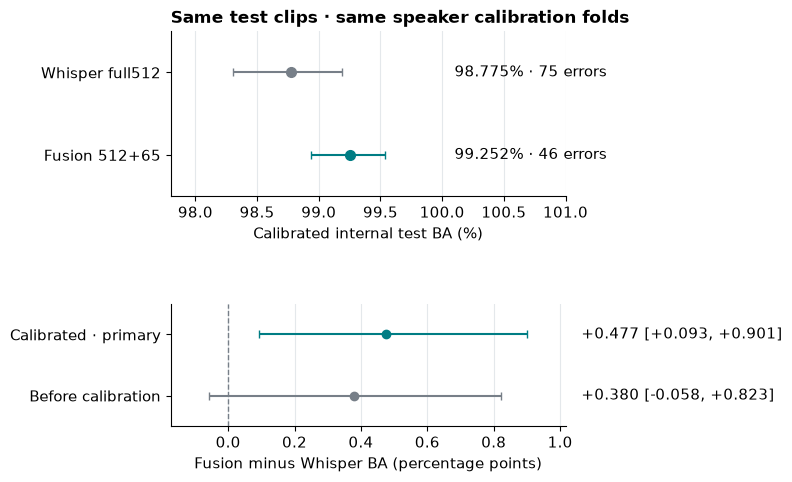

,model,median_ms,observations,observed_p95_ms,artifact_MiB
0,Fusion SVM 512+65 (A2),4.059760,60,6.627439,15.284667
1,Whisper full512 SVM,4.117734,60,6.401340,12.133780


In [7]:
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,'axes.titlesize':12,
                     'axes.spines.top':False,'axes.spines.right':False})
COLORS={WHISPER:'#777F88',FUSION:'#007D84'}
fig,axes=plt.subplots(2,1,figsize=(8.4,5.0),gridspec_kw={'height_ratios':[1.35,1]})
for i,name in enumerate(NAMES):
    row=metrics.loc[metrics.model.eq(name)&metrics['mode'].eq('calibrated')].iloc[0]
    v=100*row.balanced_accuracy;low=100*row.balanced_accuracy_ci95_low;high=100*row.balanced_accuracy_ci95_high
    axes[0].errorbar(v,i,xerr=[[v-low],[high-v]],fmt='o',capsize=3,ms=7,color=COLORS[name])
    axes[0].text(100.1,i,f'{v:.3f}% · {int(row.errors)} errors',va='center')
axes[0].set(yticks=[0,1],yticklabels=['Whisper full512','Fusion 512+65'],xlim=(97.8,101.0),ylim=(1.5,-.5),xlabel='Calibrated internal test BA (%)')
axes[0].set_title('Same test clips · same speaker calibration folds',loc='left',fontweight='bold')
for i,mode in enumerate(['calibrated','raw']):
    row=paired.loc[paired['mode'].eq(mode)&paired.metric.eq('balanced_accuracy')].iloc[0]
    v=100*row.difference;lo=100*row.ci95_low;hi=100*row.ci95_high
    axes[1].errorbar(v,i,xerr=[[v-lo],[hi-v]],fmt='o',capsize=3,color='#007D84' if mode=='calibrated' else '#777F88')
    axes[1].text(1.04,i,f'{v:+.3f} [{lo:+.3f}, {hi:+.3f}]',transform=axes[1].get_yaxis_transform(),va='center')
axes[1].axvline(0,color='#777F88',ls='--',lw=1)
lo=min(0,float(paired.loc[paired.metric.eq('balanced_accuracy'),'ci95_low'].min()*100))
hi=max(0,float(paired.loc[paired.metric.eq('balanced_accuracy'),'ci95_high'].max()*100))
span=max(.4,hi-lo);axes[1].set(xlim=(lo-.12*span,hi+.12*span),ylim=(1.5,-.5),yticks=[0,1],yticklabels=['Calibrated · primary','Before calibration'],xlabel='Fusion minus Whisper BA (percentage points)')
for ax in axes:ax.grid(axis='x',color='#E4E8EB');ax.set_axisbelow(True)
fig.subplots_adjust(left=.24,right=.71,bottom=.12,top=.91,hspace=.75)
fig.savefig(OUT/'comparison.png',dpi=180,bbox_inches='tight');plt.show();plt.close(fig)

latency=[];positions=np.linspace(0,len(test)-1,60,dtype=int)
with threadpool_limits(limits=4):
    for name in NAMES:MODELS[name].predict_proba(X[name][test[:4]])
    for repeat,idx in enumerate(positions):
        for name in (NAMES if repeat%2==0 else NAMES[::-1]):
            t=perf_counter();MODELS[name].predict_proba(X[name][test[idx:idx+1]])
            latency.append(dict(model=name,repeat=repeat,milliseconds=1000*(perf_counter()-t)))
latency=pd.DataFrame(latency);latency.to_csv(OUT/'latency_samples.csv',index=False)
latency_summary=latency.groupby('model').milliseconds.agg(median_ms='median',observations='size').reset_index()
latency_summary['observed_p95_ms']=[float(np.quantile(latency.loc[latency.model.eq(n),'milliseconds'],.95)) for n in latency_summary.model]
latency_summary['artifact_MiB']=[MODEL_INFO[n]['artifact_bytes']/2**20 for n in latency_summary.model]
latency_summary.to_csv(OUT/'latency_summary.csv',index=False)
display(latency_summary)

## 7. Save the compact result and verify replay

Reload both fitted artifacts and reproduce their saved test probabilities and classes. Check that source notebooks, caches and the service configuration did not change. Save a compact report, metrics, split/fold records and hashes. Keep fitted binaries in the source output folder; copy the completed notebook and portable evidence to the report archive after execution.

In [8]:
verification=[]
with threadpool_limits(limits=4):
    for name in NAMES:
        model=joblib.load(OUT/(SLUG[name]+'_calibrated.joblib'))
        saved=predictions.loc[predictions.model.eq(name)&predictions['mode'].eq('calibrated')]
        prob=model.predict_proba(X[name][test])[:,1]
        np.testing.assert_allclose(prob,saved.p_singapore,rtol=1e-10,atol=1e-12)
        np.testing.assert_array_equal((prob>=.5).astype(int),saved.prediction)
        verification.append(dict(model=name,class_differences=0,max_probability_difference=float(np.max(abs(prob-saved.p_singapore.to_numpy())))))
for path,expected in INPUT_HASHES.items():assert sha(path)==expected,path

def mdtable(headers,rows):
    return '\n'.join(['| '+' | '.join(headers)+' |','| '+' | '.join(['---']*len(headers))+' |']+['| '+' | '.join(map(str,r))+' |' for r in rows])
cal=metrics.loc[metrics['mode'].eq('calibrated')].set_index('model')
raw=metrics.loc[metrics['mode'].eq('raw')].set_index('model')
result_rows=[]
for name in NAMES:
    r=cal.loc[name]
    result_rows.append([name,f'{100*r.balanced_accuracy:.3f}%',f'{r.macro_f1:.6f}',f'{int(r.false_positive)} / {int(r.false_negative)}',str(int(r.errors))])
comparison_rows=[[r['mode'],r['metric'],f"{100*r['difference']:+.3f}",f"[{100*r['ci95_low']:+.3f}, {100*r['ci95_high']:+.3f}]"] for r in comparisons]
probability_rows=[[name,f'{cal.loc[name].brier_score:.6f}',f'{cal.loc[name].log_loss:.6f}',f'{cal.loc[name].roc_auc:.6f}'] for name in NAMES]
source_wide=source.loc[source['mode'].eq('calibrated')].pivot(index='source',columns='model',values='errors')
source_summary=source.loc[source['mode'].eq('calibrated')&source.model.eq(WHISPER)].set_index('source')
source_table=[[src,f'{int(source_summary.loc[src].clips)} / {int(source_summary.loc[src].speakers)}',int(source_wide.loc[src,WHISPER]),int(source_wide.loc[src,FUSION])] for src in source_wide.index]
report=f"""# A2: frozen full512 Whisper versus full512+65 fusion

Run date: {datetime.now(timezone.utc).astimezone().strftime('%d %B %Y')}.

**ANSWER** {ANSWER}

The calibrated BA difference is **{100*primary.difference:+.3f} [{100*primary.ci95_low:+.3f}, {100*primary.ci95_high:+.3f}] percentage points**. This is the primary comparison. The interval resamples whole speakers within each class. It does not include model fitting or selection uncertainty.

![Matched full512 and fusion comparison](comparison.png)

## Calibrated test results

{mdtable(['Model','Test BA','Macro F1','FP / FN','Errors'],result_rows)}

Both models use the same 6,119 test clips from 1,482 speakers. Singapore has 3,034 clips; non-Singapore has 3,085. Both use p ≥ 0.50.

{mdtable(['Mode','Metric','Change (points)','95% speaker interval'],comparison_rows)}

Fusion is correct on {int(primary.candidate_only_correct)} disagreements. Whisper is correct on {int(primary.reference_only_correct)}. Total disagreements: {int(primary.prediction_disagreements)}.

## Probability quality

{mdtable(['Model','Brier score ↓','Log loss ↓','ROC AUC'],probability_rows)}

There is no paired probability-loss interval in this run. Lower observed loss alone does not establish a population gain.

## Source errors

{mdtable(['Source','Clips / speakers','Whisper errors','Fusion errors'],source_table)}

Each source has one class. Scores cannot separate accent cues from source cues. The two small sources have only 8 and 18 test speakers.

## Fixed method

| Item | Rule |
| --- | --- |
| Encoder | Frozen openai/whisper-base.en; revision {provenance['resolved_revision']} |
| Acoustic columns | A1 permutation ranking on original training clips only; fixed count 65 |
| Split | Train 27,797; validation 6,084; test 6,119; no speaker overlap |
| Development | 33,881 clips; 8,443 speakers |
| C grid | 0.01, 0.1, 1, 10; validation BA, macro F1, smaller C |
| Selected C | Whisper: {CHOSEN[WHISPER]:g}; fusion: {CHOSEN[FUSION]:g} |
| Whisper search | Reused verified completed E2 search |
| Fusion search | New training-only C trials; no PCA |
| Branch weights | Acoustic: 1/√65; Whisper: 1/√512 |
| Calibration | Same five development speaker folds; sigmoid; ensemble=False |
| Primary | Calibrated fusion minus calibrated Whisper BA; p ≥ 0.50 |
| Secondary | Raw BA, macro F1, source errors, probability loss and cached-head cost |
| Bootstrap | 2,000 paired whole-speaker draws within each class; seed 42 |

## Limits and use

- This test was inspected before this experiment. The result is retrospective. No multiple-comparison correction is applied.
- Acoustic selection uses training clips only. Calibration folds keep columns and C fixed. They do not estimate the complete selection process.
- Source and class are linked. Add new speakers and a second Singapore source for a stronger generalization claim.
- This A2 fusion refit uses different acoustic columns from the 28 October release candidate. Do not assign its scores to that saved candidate.
- The internal test and the earlier 9,000-clip benchmark are not independent. This run does not rerun that benchmark.
- Single-request timings exclude feature extraction, loading, concurrency and the service. They describe this host only.
- No service model or manifest is changed.

## Saved evidence

- `test_predictions.csv`: both thresholds and probabilities for both models.
- `test_metrics.csv`, `paired_comparisons.csv`, `source_metrics.csv`: exact values.
- `validation_trials.csv`, `selected_C.json`, `calibration_folds.csv`: selection and fold records.
- `latency_samples.csv`, `latency_summary.csv`: warm cached-head measurements.
- `protocol.json`, `model_contracts.json`, `run_record.json`: code/input hashes, model contracts and replay checks.
- Fitted artifacts stay in `{OUT}`. Their paths and checksums are in the model contracts.
"""
(OUT/'report.md').write_text(report)
files={p.name:sha(p) for p in OUT.iterdir() if p.is_file() and p.name!='run_record.json'}
record=dict(status='complete',study='E4.02.5 / A2',started_utc=START,completed_utc=datetime.now(timezone.utc).isoformat(),
    signature=SIGNATURE,code_sha256=CODE_SHA,primary_result=primary.to_dict(),answer=ANSWER,retrospective=True,
    test_clips=len(test),test_speakers=truth.speaker_group.nunique(),input_hashes=INPUT_HASHES,
    selected_columns=COLS.tolist(),selected_feature_names=feature_names,selected_C=CHOSEN,
    calibration_fold_sha256=fold_hash,replay_verification=verification,source_files_unchanged=True,
    generated_files=files,packages=PACKAGES,models=MODEL_INFO,
    interval_scope='fixed fitted models; excludes fitting/selection uncertainty',
    distinction='A2 training-only acoustic columns; not the development-ranked 28 Oct candidate')
write_json(OUT/'run_record.json',record)
display(Markdown(report))
print('COMPLETE:',OUT,flush=True)

# A2: frozen full512 Whisper versus full512+65 fusion

Run date: 29 October 2026.

**ANSWER** Fusion has a positive calibrated BA difference on this retrospective test.

The calibrated BA difference is **+0.477 [+0.093, +0.901] percentage points**. This is the primary comparison. The interval resamples whole speakers within each class. It does not include model fitting or selection uncertainty.

![Matched full512 and fusion comparison](comparison.png)

## Calibrated test results

| Model | Test BA | Macro F1 | FP / FN | Errors |
| --- | --- | --- | --- | --- |
| Whisper full512 SVM | 98.775% | 0.987742 | 41 / 34 | 75 |
| Fusion SVM 512+65 (A2) | 99.252% | 0.992482 | 36 / 10 | 46 |

Both models use the same 6,119 test clips from 1,482 speakers. Singapore has 3,034 clips; non-Singapore has 3,085. Both use p ≥ 0.50.

| Mode | Metric | Change (points) | 95% speaker interval |
| --- | --- | --- | --- |
| calibrated | balanced_accuracy | +0.477 | [+0.093, +0.901] |
| calibrated | macro_f1 | +0.474 | [+0.082, +0.903] |
| raw | balanced_accuracy | +0.380 | [-0.058, +0.823] |
| raw | macro_f1 | +0.376 | [-0.084, +0.830] |

Fusion is correct on 55 disagreements. Whisper is correct on 26. Total disagreements: 81.

## Probability quality

| Model | Brier score ↓ | Log loss ↓ | ROC AUC |
| --- | --- | --- | --- |
| Whisper full512 SVM | 0.009587 | 0.036127 | 0.999089 |
| Fusion SVM 512+65 (A2) | 0.005747 | 0.020413 | 0.999769 |

There is no paired probability-loss interval in this run. Lower observed loss alone does not establish a population gain.

## Source errors

| Source | Clips / speakers | Whisper errors | Fusion errors |
| --- | --- | --- | --- |
| common_voice | 2913 / 1241 | 22 | 20 |
| mnsc | 3034 / 215 | 34 | 10 |
| speech_accent_archive | 50 / 8 | 1 | 3 |
| speechocean762 | 122 / 18 | 18 | 13 |

Each source has one class. Scores cannot separate accent cues from source cues. The two small sources have only 8 and 18 test speakers.

## Fixed method

| Item | Rule |
| --- | --- |
| Encoder | Frozen openai/whisper-base.en; revision 911407f4214e0e1d82085af863093ec0b66f9cd6 |
| Acoustic columns | A1 permutation ranking on original training clips only; fixed count 65 |
| Split | Train 27,797; validation 6,084; test 6,119; no speaker overlap |
| Development | 33,881 clips; 8,443 speakers |
| C grid | 0.01, 0.1, 1, 10; validation BA, macro F1, smaller C |
| Selected C | Whisper: 10; fusion: 10 |
| Whisper search | Reused verified completed E2 search |
| Fusion search | New training-only C trials; no PCA |
| Branch weights | Acoustic: 1/√65; Whisper: 1/√512 |
| Calibration | Same five development speaker folds; sigmoid; ensemble=False |
| Primary | Calibrated fusion minus calibrated Whisper BA; p ≥ 0.50 |
| Secondary | Raw BA, macro F1, source errors, probability loss and cached-head cost |
| Bootstrap | 2,000 paired whole-speaker draws within each class; seed 42 |

## Limits and use

- This test was inspected before this experiment. The result is retrospective. No multiple-comparison correction is applied.
- Acoustic selection uses training clips only. Calibration folds keep columns and C fixed. They do not estimate the complete selection process.
- Source and class are linked. Add new speakers and a second Singapore source for a stronger generalization claim.
- This A2 fusion refit uses different acoustic columns from the 28 October release candidate. Do not assign its scores to that saved candidate.
- The internal test and the earlier 9,000-clip benchmark are not independent. This run does not rerun that benchmark.
- Single-request timings exclude feature extraction, loading, concurrency and the service. They describe this host only.
- No service model or manifest is changed.

## Saved evidence

- `test_predictions.csv`: both thresholds and probabilities for both models.
- `test_metrics.csv`, `paired_comparisons.csv`, `source_metrics.csv`: exact values.
- `validation_trials.csv`, `selected_C.json`, `calibration_folds.csv`: selection and fold records.
- `latency_samples.csv`, `latency_summary.csv`: warm cached-head measurements.
- `protocol.json`, `model_contracts.json`, `run_record.json`: code/input hashes, model contracts and replay checks.
- Fitted artifacts stay in `/home/mh/nusproj/singlish-whisper/outputs/e4_02_5_frozen_full512_vs_fusion_calibrated_20261029`. Their paths and checksums are in the model contracts.


COMPLETE: /home/mh/nusproj/singlish-whisper/outputs/e4_02_5_frozen_full512_vs_fusion_calibrated_20261029
